In [13]:
import math 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal
from scipy.signal import iirnotch, sosfilt, tf2sos
from scipy.ndimage import gaussian_filter1d

from plot_helpers import plot_signal, plot_emg_vs_joystick, plot_frequencies

In [14]:
def notch_cascade_sos(fs, base=50.0, q=30.0):
    """Cascada de notches en base, 2*base, 3*base, ... < Nyquist*0.95.
    Mismo diseno que monitor.py."""
    nyq = fs / 2
    sections = []
    f = base
    while f < nyq * 0.95:
        b, a = iirnotch(f, q, fs=fs)
        sections.append(tf2sos(b, a))
        f += base
    return np.vstack(sections) if sections else None

def causal_notch(x, sos):
    """Aplica la cascada notch causalmente (sosfilt, no sosfiltfilt)."""
    if sos is None:
        return np.asarray(x)
    return sosfilt(sos, np.asarray(x))

def causal_bandpass(x, fs, low=70, high=233, order=4):
    b, a = signal.butter(order, [low, high], btype="bandpass", fs=fs)
    return signal.lfilter(b, a, x)

def rolling_rms(x, fs, window_ms=50):
    w = max(1, int(fs * window_ms / 1000))
    x2 = np.asarray(x) ** 2
    kernel = np.ones(w) / w
    return np.sqrt(np.convolve(x2, kernel, mode="same"))

def preprocess_emg_rms(df, fs, window_ms=50, notch_base=50.0, notch_q=30.0):
    df = df.copy()
    sos = notch_cascade_sos(fs, notch_base, notch_q)

    df["emg_ext_bp"]  = causal_bandpass(causal_notch(df["emg0"].values, sos), fs)
    df["emg_flex_bp"] = causal_bandpass(causal_notch(df["emg1"].values, sos), fs)

    df["ext_rms"]  = rolling_rms(df["emg_ext_bp"].values,  fs, window_ms)
    df["flex_rms"] = rolling_rms(df["emg_flex_bp"].values, fs, window_ms)

    return df

def preprocess_emg_butter(df, fs, low_pass_hz=1, notch_base=50.0, notch_q=30.0):
    df = df.copy()
    sos = notch_cascade_sos(fs, notch_base, notch_q)

    df["emg_ext_bp"]  = causal_bandpass(causal_notch(df["emg0"].values, sos), fs)
    df["emg_flex_bp"] = causal_bandpass(causal_notch(df["emg1"].values, sos), fs)

    df["emg_ext_rect"]  = np.abs(df["emg_ext_bp"])
    df["emg_flex_rect"] = np.abs(df["emg_flex_bp"])

    b_lp, a_lp = signal.butter(2, low_pass_hz, btype="lowpass", fs=fs)
    df["ext_env"]  = signal.filtfilt(b_lp, a_lp, df["emg_ext_rect"])
    df["flex_env"] = signal.filtfilt(b_lp, a_lp, df["emg_flex_rect"])

    return df

def smooth_signal(x, fs, lp_hz=5):
    b, a = signal.butter(2, lp_hz, btype="lowpass", fs=fs)
    return signal.filtfilt(b, a, x)


def gaussian_smooth_target(x, fs, sigma_ms=150):
    sigma_samples = sigma_ms / 1000 * fs
    return gaussian_filter1d(
        x.astype(float),
        sigma=sigma_samples,
        mode="nearest"
    )

def standardize(x):
    return (x - x.mean())/x.std()

In [22]:

CSV_PATH = "./data/debug/test_ok.csv"   # ajustar al archivo a analizar
df = pd.read_csv(CSV_PATH)

df["t"] = df["t_micros"] * 1e-6

df["emg0"] -= df["emg0"].mean()
df["emg1"] -= df["emg1"].mean()
df["emg2"] -= df["emg2"].mean()
df["emg3"] -= df["emg3"].mean()

dt = np.diff(df["t"])
fs = 1 / np.mean(dt)
print("Sampling frequency:", fs, "Hz")
print("Sampling Standard Deviation:", dt.std(), "Hz")

df["y_top"] = gaussian_smooth_target(-df["joy_a"] + 1830, fs, 50)
df["y_bottom"] = gaussian_smooth_target(-df["joy_b"] + 1893, fs, 50)
df["joy"] = df["y_top"] + df["y_bottom"]

df.dropna(inplace=True)

print(len(df))
df.head()

Sampling frequency: 691.1601486864304 Hz
Sampling Standard Deviation: 5.397274305365459e-06 Hz
6993


,pc_timestamp,t_micros,emg0,emg1,emg2,emg3,joy_a,joy_b,t,y_top,y_bottom,joy
0,1.781655e+09,1.868341e+09,-316860.011583,-827731.214357,3.591262e+06,3.456621e+06,1717.0,1799.0,1868.340612,47.154754,62.886674,110.041428
1,1.781655e+09,1.868342e+09,-59949.011583,-281581.214357,3.591262e+06,3.457129e+06,1971.0,1957.0,1868.342063,45.555856,61.945320,107.501176
2,1.781655e+09,1.868344e+09,238021.988417,289216.785643,3.591262e+06,3.437523e+06,1933.0,1952.0,1868.343517,43.952221,60.991939,104.944160
3,1.781655e+09,1.868345e+09,356834.988417,584552.785643,-2.675898e+05,3.434930e+06,1865.0,1788.0,1868.344959,42.345026,60.028547,102.373573
4,1.781655e+09,1.868346e+09,323505.988417,616329.785643,6.124142e+05,3.129079e+06,1843.0,1747.0,1868.346404,40.735067,59.055611,99.790678


In [30]:
df = preprocess_emg_rms(df, fs, window_ms=200)
df = preprocess_emg_butter(df, fs, low_pass_hz=1)

gain_flex = df["ext_env"].std() / df["flex_env"].std()

df["activity"] = (standardize(df["ext_rms"]) - standardize(df["flex_rms"]))

df = df.iloc[300:-100].reset_index(drop=True)

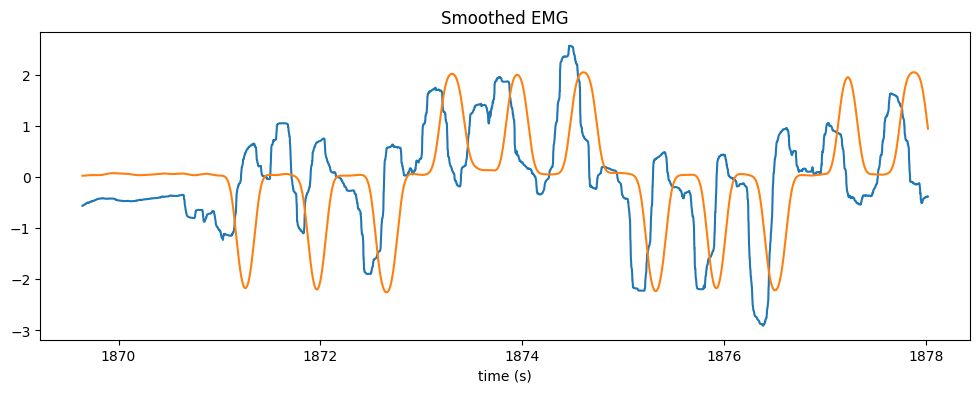

In [31]:
plot_emg_vs_joystick(df["t"], standardize(df["activity"]), standardize(df["joy"]))

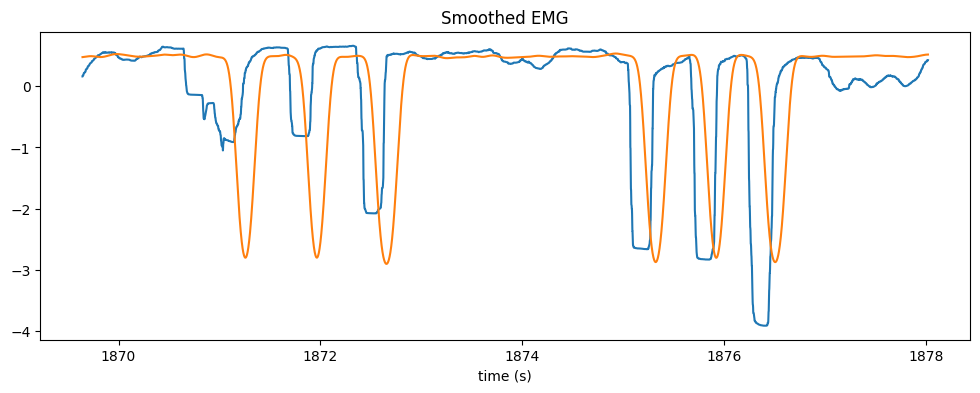

In [32]:
plot_emg_vs_joystick(df["t"], -standardize(df["flex_rms"]), standardize(df["y_bottom"]))

ValueError: x and y must have same first dimension, but have shapes (6193,) and (6593,)

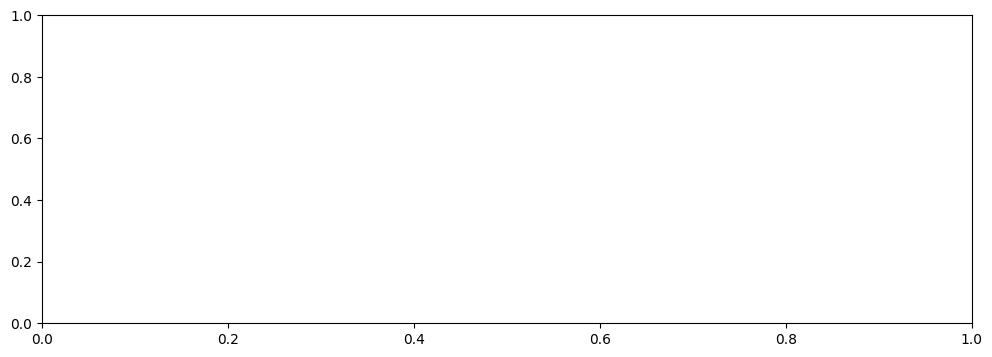

In [27]:
plot_emg_vs_joystick(df["t"], std_ext_rms, standardize(df["y_top"]))